# HybridMSLATNet: multi-source training (APTOS + DDR), IDRiD kept untouched

**Design fixed in advance (do not change after seeing results):**
- Training data: APTOS train (cleaned) + DDR train (cleaned, own split), sampled uniformly.
- Validation: APTOS val and DDR val separately. **Model selection = mean of the two validation QWKs.**
- Test: APTOS test and DDR held-out test, evaluated once at the end.
- **IDRiD is never used for training, validation or model selection.** Evaluate it once, in the very last cell, after training has finished.

**How to run:** top to bottom, on a **GPU runtime**. Smoke test first: set `"epochs": 2` and `"tag": "mssmoke"`, run everything up to the training cell, check there are no errors and note the time of one epoch, then stop. For the real run set `"epochs"` (about 20) and `"tag": "ms"` and change `SEED` only for extra seeds.

Needs in Drive: `aptos_clean_split.csv`, `ddr_clean_split.csv`, the APTOS zip (`archive.zip`) and the DDR zip.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install timm pennylane pennylane-lightning -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 79.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 117.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 19.5 MB/s eta 0:00:00


In [ ]:
import os, zipfile

# --- APTOS ---
if not os.path.exists("/content/APTOS"):
    with zipfile.ZipFile("/content/drive/MyDrive/your folder.zip", 'r') as z:
        z.extractall("/content/APTOS")
print("APTOS ready:", os.listdir("/content/APTOS"))

# --- DDR ---
DDR_ZIP = "/content/drive/MyDrive/your folder.zip"        # <-- CHANGE to the real path of your DDR zip
if not os.path.exists("/content/ddr/DR_grading.csv"):
    os.system(f'unzip -q "{DDR_ZIP}" -d /content/ddr')
print("DDR ready:", os.listdir("/content/ddr"))

APTOS ready: ['test.csv', 'train_1.csv', 'test_images', 'valid.csv', 'train_images', 'val_images']
DDR ready: ['DR_grading.csv', 'DR_grading']


## 2. Imports and configuration

In [ ]:
import os, random, hashlib
import numpy as np, pandas as pd, torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm import tqdm
import timm
import pennylane as qml
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, roc_auc_score, classification_report, confusion_matrix)

In [ ]:
BASE_PATH = "/content/drive/MyDrive/your folder"
os.makedirs(BASE_PATH + "/checkpoints", exist_ok=True)

SEED = 42          # 42, 43, 44

config = {
    "epochs": 20,            # decide after timing one epoch (see the first cell)
    "batch_size": 32,
    "num_classes": 5,
    "lr_backbone": 1e-4,
    "lr_other": 1e-4,
    "lr_alpha": 1e-2,
    "weight_decay": 0.01,

    "quantum_mode": "circuit",   # "circuit" | "skip"
    "fixed_alpha": None,
    "use_pos_emb": False,
    "n_trans_layers": 4,

    "tag": "ms",
}

RUN = (f"{config['tag']}_" if config["tag"] else "") + \
      f"{config['quantum_mode']}_a{config['fixed_alpha']}_pe{int(config['use_pos_emb'])}_L{config['n_trans_layers']}_s{SEED}"
print("RUN name:", RUN)

RUN name: ms_circuit_aNone_pe0_L4_s42


## 3. Augmentation (same as the APTOS-only experiments)

In [ ]:
train_tf = A.Compose([
    A.Resize(256, 256),
    A.RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0)),
    A.HorizontalFlip(),
    A.VerticalFlip(),
    A.Rotate(limit=15),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

val_tf = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

## 4. Data: APTOS (cleaned) + DDR (cleaned), cached once at 256x256 (area interpolation)

In [ ]:
import cv2
from concurrent.futures import ThreadPoolExecutor

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# ---------- APTOS: the cleaned split saved earlier ----------
APT_ROOT = "/content/APTOS"
ap_dir = {"train": f"{APT_ROOT}/train_images/train_images",
          "val":   f"{APT_ROOT}/val_images/val_images",
          "test":  f"{APT_ROOT}/test_images/test_images"}
ap = pd.read_csv(BASE_PATH + "/aptos_clean_split.csv")[["id_code", "diagnosis", "split"]].copy()
ap["source"] = "aptos"
ap["src_path"] = [f"{ap_dir[s]}/{i}.png" for s, i in zip(ap.split, ap.id_code)]
ap["cache"] = [f"/content/cache_aptos/{i}.png" for i in ap.id_code]

# ---------- DDR: the cleaned split from ddr_prep ----------
DDR_DIR = "/content/ddr"
by_name = {}
for root, _, files in os.walk(DDR_DIR):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")):
            by_name.setdefault(f, []).append(os.path.join(root, f))
dd = pd.read_csv(BASE_PATH + "/ddr_clean_split.csv")[["id_code", "diagnosis", "split"]].copy()
dd["source"] = "ddr"
missing = [n for n in dd.id_code if n not in by_name]
assert not missing, f"{len(missing)} DDR images not found, e.g. {missing[:3]}"
dd["src_path"] = dd.id_code.map(lambda n: by_name[n][0])
dd["cache"] = [f"/content/cache_ddr/{i}.png" for i in dd.id_code]

alldf = pd.concat([ap, dd], ignore_index=True)
alldf["diagnosis"] = alldf["diagnosis"].astype(int)
for d in ("/content/cache_aptos", "/content/cache_ddr"): os.makedirs(d, exist_ok=True)

def cache_one(a):
    s, d = a
    if not os.path.exists(d):
        im = cv2.imread(s)
        if im is None: raise RuntimeError("cannot read " + s)
        cv2.imwrite(d, cv2.resize(im, (256, 256), interpolation=cv2.INTER_AREA))
with ThreadPoolExecutor(4) as ex:
    list(tqdm(ex.map(cache_one, zip(alldf.src_path, alldf.cache)), total=len(alldf)))

print(alldf.groupby(["source", "split"]).size().unstack().to_string())
for (s, sp), g in alldf.groupby(["source", "split"]):
    print(f"{s:6s} {sp:5s} {len(g):6d}", np.bincount(g.diagnosis, minlength=5))

# ---------- datasets and loaders ----------
class CachedDS(Dataset):
    def __init__(self, df, tf):
        self.p, self.y, self.t = df.cache.tolist(), df.diagnosis.astype(int).tolist(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        im = cv2.cvtColor(cv2.imread(self.p[i]), cv2.COLOR_BGR2RGB)
        return self.t(image=im)["image"], self.y[i]

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

bs = config["batch_size"]
g = torch.Generator(); g.manual_seed(SEED)
train_df = alldf[alldf.split == "train"]
train_loader = DataLoader(CachedDS(train_df, train_tf), batch_size=bs, shuffle=True, num_workers=2, pin_memory=True,
                          generator=g, worker_init_fn=seed_worker, drop_last=True)
mk = lambda df: DataLoader(CachedDS(df, val_tf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
val_loaders  = {s: mk(alldf[(alldf.split == "val")  & (alldf.source == s)]) for s in ("aptos", "ddr")}
test_loaders = {s: mk(alldf[(alldf.split == "test") & (alldf.source == s)]) for s in ("aptos", "ddr")}
print("training images:", len(train_df), "| steps per epoch:", len(train_loader))

100%|██████████| 15928/15928 [08:03<00:00, 32.92it/s] 


split   test  train   val
source                   
aptos    339   2824   341
ddr     1864   8696  1864
aptos  test     339 [197  28  75  12  27]
aptos  train   2824 [1427  277  756  145  219]
aptos  val      341 [172  33  91  20  25]
ddr    test    1864 [926  94 672  35 137]
ddr    train   8696 [4317  441 3134  165  639]
ddr    val     1864 [925  95 671  36 137]
training images: 11520 | steps per epoch: 360


## 5. Quantum circuit (8 qubits, 3 layers, data re-uploading, ring CNOT) - classical simulator, backpropagation

In [ ]:
n_qubits = 8
n_layers = 3

dev = qml.device("default.qubit", wires=n_qubits)

def quantum_circuit(inputs, weights):
    for i in range(n_qubits):                       # initial U3 encoding
        qml.U3(inputs[..., i], inputs[..., i], inputs[..., i], wires=i)
    for l in range(n_layers):
        for i in range(n_qubits):                   # data re-uploading
            qml.RY(inputs[..., i], wires=i)
        for i in range(n_qubits):                   # trainable single-qubit rotations (72 parameters in total)
            qml.U3(weights[l][i][0], weights[l][i][1], weights[l][i][2], wires=i)
        for i in range(n_qubits):                   # ring entanglement
            qml.CNOT(wires=[i, (i + 1) % n_qubits])
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (n_layers, n_qubits, 3)}
qnode = qml.QNode(quantum_circuit, dev, interface="torch", diff_method="backprop")

In [ ]:
class QuantumBranch(nn.Module):
    """256 -> attention gate -> reducer -> 8 angles -> (circuit | control) -> 8 features"""
    def __init__(self, feature_dim=256, mode="circuit"):
        super().__init__()
        self.mode = mode

        self.attn = nn.Sequential(
            nn.Linear(feature_dim, 64), nn.ReLU(), nn.Linear(64, feature_dim)
        )
        self.reducer = nn.Sequential(
            nn.Linear(feature_dim, 256), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(256, 128),         nn.GELU(), nn.Dropout(0.2),
            nn.Linear(128, 64),          nn.GELU(), nn.Dropout(0.2),
            nn.Linear(64, n_qubits)
        )

        if mode in ("circuit", "frozen"):
            self.quantum = qml.qnn.TorchLayer(qnode, weight_shapes)   # a fresh circuit for every model
            if mode == "frozen":                                      # random circuit that is never trained
                for p in self.quantum.parameters():
                    p.requires_grad_(False)
        elif mode == "mlp":                                           # matched classical layer: 8*8 + 8 = 72 parameters
            self.quantum = nn.Sequential(nn.Linear(n_qubits, n_qubits), nn.Tanh())
        elif mode == "skip":                                          # no circuit at all
            self.quantum = None
        else:
            raise ValueError(f"unknown quantum_mode: {mode}")

    def forward(self, x):
        a = torch.softmax(self.attn(x), dim=-1)
        x = x * a
        x = self.reducer(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = torch.tanh(x) * np.pi                       # 8 angles in (-pi, pi)

        if self.mode in ("circuit", "frozen"):
            q_out = self.quantum(x.float())
        elif self.mode == "mlp":
            q_out = self.quantum(x.float() / np.pi)
        else:                                            # "skip": same 8 numbers, scaled to (-1, 1) like the circuit output
            q_out = x.float() / np.pi
        return q_out, x

In [ ]:
class HybridMSLATNet(nn.Module):
    def __init__(self, num_classes=5, embed_dim=256, n_trans_layers=4, use_pos_emb=False,
                 quantum_mode="circuit", fixed_alpha=None):
        super().__init__()

        self.backbone = timm.create_model("efficientnet_b2", pretrained=True, features_only=True)
        feat_dims = [f["num_chs"] for f in self.backbone.feature_info[-3:]]

        self.proj = nn.ModuleList([nn.Linear(feat_dims[i], embed_dim) for i in range(3)])

        # optional learned position / scale embeddings (one vector per token of the concatenated sequence)
        self.pos_emb = None
        if use_pos_emb:
            was_training = self.backbone.training
            self.backbone.eval()
            with torch.no_grad():
                fs = self.backbone(torch.zeros(1, 3, 224, 224))[-3:]
            n_tokens = sum(f.shape[2] * f.shape[3] for f in fs)
            self.backbone.train(was_training)
            self.pos_emb = nn.Parameter(torch.zeros(1, n_tokens, embed_dim))
            nn.init.trunc_normal_(self.pos_emb, std=0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=8, dim_feedforward=embed_dim * 4,
            dropout=0.5, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=n_trans_layers, enable_nested_tensor=False)

        self.pool = nn.Linear(embed_dim, 1)

        self.classical_head = nn.Sequential(
            nn.Linear(embed_dim, 128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, 64),        nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

        self.quantum_branch = QuantumBranch(embed_dim, mode=quantum_mode)

        self.fusion_head = nn.Sequential(
            nn.Linear(embed_dim + n_qubits, 256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        self.quantum_head = nn.Sequential(
            nn.Linear(n_qubits, 32), nn.GELU(), nn.Linear(32, num_classes)
        )

        # mixing weight between the classical and the fused prediction
        self.learn_alpha = fixed_alpha is None
        if self.learn_alpha:
            self.alpha = nn.Parameter(torch.tensor(-1.0))               # sigmoid(-1) = 0.269 at the start
        else:
            self.register_buffer("alpha", torch.tensor(float(fixed_alpha)))

    def get_alpha(self):
        return torch.sigmoid(self.alpha) if self.learn_alpha else self.alpha

    def forward(self, x):
        feats = self.backbone(x)[-3:]

        tokens = []
        for i, f in enumerate(feats):
            t = f.flatten(2).transpose(1, 2)          # (B, H*W, C): every spatial position is one token
            tokens.append(self.proj[i](t))
        tokens = torch.cat(tokens, dim=1)
        if self.pos_emb is not None:
            tokens = tokens + self.pos_emb
        tokens = self.transformer(tokens)

        attn = torch.softmax(self.pool(tokens), dim=1)
        pooled = (tokens * attn).sum(dim=1)            # (B, 256)

        classical_logits = self.classical_head(pooled)

        quantum_features, q_input = self.quantum_branch(pooled)
        fusion_logits  = self.fusion_head(torch.cat([pooled, quantum_features], dim=1))
        quantum_logits = self.quantum_head(quantum_features)

        alpha = self.get_alpha()
        out = (1 - alpha) * classical_logits + alpha * fusion_logits

        return out, classical_logits, quantum_logits, pooled, attn, q_input

## 6. Losses

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2, smoothing=0.05):
        super().__init__()
        self.gamma, self.smoothing = gamma, smoothing

    def forward(self, logits, targets, reduction="mean"):
        logits = logits.float()
        K = logits.size(1)
        with torch.no_grad():
            t = torch.full_like(logits, self.smoothing / (K - 1))
            t.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        ce = -(t * F.log_softmax(logits, dim=1)).sum(dim=1)
        loss = (1 - torch.exp(-ce)) ** self.gamma * ce
        return loss if reduction == "none" else loss.mean()

def ordinal_loss(logits, targets):
    # P(grade <= j) must be 0 for j < true grade and 1 for j >= true grade
    cum = torch.cumsum(torch.softmax(logits.float(), dim=1), dim=1)
    idx = torch.arange(cum.size(1), device=cum.device).unsqueeze(0)
    tgt = (idx >= targets.unsqueeze(1)).float()
    return F.mse_loss(cum, tgt)

def compute_total_loss(hybrid_logits, classical_logits, quantum_logits, targets, focal_fn):
    w = torch.ones_like(targets, dtype=torch.float32)
    w[targets >= 3] = 1.5                                            # per-sample severity weight
    hybrid_loss    = (w * focal_fn(hybrid_logits, targets, "none")).mean()
    classical_loss = focal_fn(classical_logits, targets)
    quantum_loss   = focal_fn(quantum_logits, targets)
    ord_loss       = ordinal_loss(hybrid_logits, targets)
    return hybrid_loss + 0.2 * quantum_loss + 0.3 * classical_loss + 0.1 * ord_loss

## 7. Create model, optimizer, scheduler

In [ ]:
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device, "| mixed precision:", use_amp)

set_seed(SEED)                                   # same starting weights for the same seed
model = HybridMSLATNet(
    n_trans_layers=config["n_trans_layers"],
    use_pos_emb=config["use_pos_emb"],
    quantum_mode=config["quantum_mode"],
    fixed_alpha=config["fixed_alpha"],
).to(device)

criterion = FocalLoss(gamma=2, smoothing=0.05)

backbone_params = list(model.backbone.parameters())
bb_ids = {id(p) for p in backbone_params}
alpha_params = [model.alpha] if model.learn_alpha else []
al_ids = {id(p) for p in alpha_params}
other_params = [p for p in model.parameters()
                if p.requires_grad and id(p) not in bb_ids and id(p) not in al_ids]

groups = [{"params": backbone_params, "lr": config["lr_backbone"]},
          {"params": other_params,    "lr": config["lr_other"]}]
if alpha_params:
    groups.append({"params": alpha_params, "lr": config["lr_alpha"], "weight_decay": 0.0})
optimizer = torch.optim.AdamW(groups, weight_decay=config["weight_decay"])

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
warmup    = LinearLR(optimizer, start_factor=0.1, total_iters=5)
cosine    = CosineAnnealingLR(optimizer, T_max=max(1, config["epochs"] - 5))
scheduler = SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[5])

# parameter counts (useful for the complexity table in the paper)
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_quant = sum(p.numel() for p in model.quantum_branch.quantum.parameters()) if model.quantum_branch.quantum is not None else 0
print(f"parameters: total {n_total/1e6:.2f} M | trainable {n_train/1e6:.2f} M | quantum/control layer {n_quant}")

device: cuda | mixed precision: True


parameters: total 10.75 M | trainable 10.75 M | quantum/control layer 72


## 8. Training
Each epoch: train on APTOS+DDR, then score on APTOS-val and DDR-val. The checkpoint with the best **mean validation QWK** is kept. IDRiD and the test sets are not touched here.

In [ ]:
best_path = f"{BASE_PATH}/checkpoints/best_{RUN}.pth"
last_path = f"{BASE_PATH}/checkpoints/last_{RUN}.pth"

@torch.no_grad()
def evaluate(loader):
    model.eval(); P, Y = [], []
    for imgs, labels in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(imgs.to(device, non_blocking=True))[0]
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); Y.append(labels.numpy())
    P = np.concatenate(P).astype(np.float64); P = P / P.sum(1, keepdims=True)
    Y = np.concatenate(Y); pred = P.argmax(1)
    L = [0, 1, 2, 3, 4]; cm = confusion_matrix(Y, pred, labels=L)
    m = dict(acc=accuracy_score(Y, pred),
             f1=f1_score(Y, pred, average="macro", labels=L, zero_division=0),
             qwk=cohen_kappa_score(Y, pred, weights="quadratic", labels=L),
             auc=roc_auc_score(Y, P, multi_class="ovr", labels=L),
             ref_auc=roc_auc_score((Y >= 2).astype(int), P[:, 2:].sum(1)),
             sens=cm[2:, 2:].sum() / cm[2:].sum(), spec=cm[:2, :2].sum() / cm[:2].sum())
    return m, P, Y, pred

start_epoch, best_sel, log = 0, -1.0, []
if os.path.exists(last_path):
    ck = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["opt"]); scheduler.load_state_dict(ck["sched"])
    start_epoch, best_sel, log = ck["epoch"] + 1, ck["best_sel"], ck["log"]
    print(f"Resuming from epoch {start_epoch}, best mean val QWK {best_sel:.4f}")

scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
import time

for epoch in range(start_epoch, config["epochs"]):
    t0 = time.time(); model.train(); run_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out, cl, ql = model(imgs)[:3]
            loss = compute_total_loss(out, cl, ql, labels, criterion)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        run_loss += loss.item()
    scheduler.step()

    vm = {s: evaluate(l)[0] for s, l in val_loaders.items()}
    sel = float(np.mean([vm[s]["qwk"] for s in vm]))
    alpha = float(model.get_alpha().detach())
    row = dict(epoch=epoch + 1, train_loss=run_loss / len(train_loader), alpha=alpha, sel_qwk=sel, minutes=(time.time() - t0) / 60)
    for s in vm: row.update({f"{s}_{k}": v for k, v in vm[s].items()})
    log.append(row)
    print(f"Ep {epoch+1:03d} ({row['minutes']:.1f} min) loss {row['train_loss']:.4f} | mean val QWK {sel:.4f} | "
          f"APTOS QWK {vm['aptos']['qwk']:.4f} acc {vm['aptos']['acc']:.4f} | DDR QWK {vm['ddr']['qwk']:.4f} acc {vm['ddr']['acc']:.4f} | alpha {alpha:.3f}")

    if sel > best_sel:
        best_sel = sel
        torch.save({"epoch": epoch, "model": model.state_dict(), "alpha": alpha, "val": vm}, best_path)
        print("   saved best")
    torch.save({"epoch": epoch, "model": model.state_dict(), "opt": optimizer.state_dict(),
                "sched": scheduler.state_dict(), "best_sel": best_sel, "log": log}, last_path)

pd.DataFrame(log).to_csv(f"{BASE_PATH}/train_log_{RUN}.csv", index=False)
print("Training finished. Best mean validation QWK:", round(best_sel, 4))

Ep 001 (3.4 min) loss 1.3281 | mean val QWK 0.0000 | APTOS QWK 0.0000 acc 0.5044 | DDR QWK 0.0000 acc 0.4962 | alpha 0.345
   saved best
Ep 002 (3.4 min) loss 0.9622 | mean val QWK 0.7891 | APTOS QWK 0.8244 acc 0.7273 | DDR QWK 0.7537 acc 0.7564 | alpha 0.469
   saved best
Ep 003 (3.4 min) loss 0.7842 | mean val QWK 0.8131 | APTOS QWK 0.8534 acc 0.7566 | DDR QWK 0.7727 acc 0.7554 | alpha 0.552
   saved best
Ep 004 (3.4 min) loss 0.6940 | mean val QWK 0.8492 | APTOS QWK 0.8892 acc 0.7889 | DDR QWK 0.8092 acc 0.8015 | alpha 0.620
   saved best
Ep 005 (3.4 min) loss 0.6220 | mean val QWK 0.8628 | APTOS QWK 0.8990 acc 0.8035 | DDR QWK 0.8267 acc 0.8165 | alpha 0.687
   saved best
Ep 006 (3.4 min) loss 0.5413 | mean val QWK 0.8574 | APTOS QWK 0.9042 acc 0.8182 | DDR QWK 0.8107 acc 0.8085 | alpha 0.742
Ep 007 (3.4 min) loss 0.4902 | mean val QWK 0.8625 | APTOS QWK 0.8878 acc 0.8152 | DDR QWK 0.8372 acc 0.8155 | alpha 0.786
Ep 008 (3.4 min) loss 0.4271 | mean val QWK 0.8726 | APTOS QWK 0.9098

## 9. Final evaluation on the APTOS and DDR TEST sets
**Run once**, after training has finished (best-validation checkpoint).

In [ ]:
ck = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
res_path = f"{BASE_PATH}/results_multisource.csv"
print(f"best epoch {ck['epoch']+1} | alpha {ck['alpha']:.3f}")
for s, l in test_loaders.items():
    tm, P, Y, pred = evaluate(l)
    print(f"\n===== {s.upper()} test ({len(Y)} images) =====")
    print({k: round(float(v), 4) for k, v in tm.items()})
    print(classification_report(Y, pred, target_names=names, digits=4, zero_division=0))
    print(confusion_matrix(Y, pred, labels=[0, 1, 2, 3, 4]))
    np.savez(f"{BASE_PATH}/test_preds_{RUN}_{s}.npz", P=P, Y=Y)
    row = dict(run=RUN, dataset=f"{s}_test", best_epoch=ck["epoch"] + 1, alpha=ck["alpha"], n=len(Y), **{k: float(v) for k, v in tm.items()})
    pd.DataFrame([row]).to_csv(res_path, mode="a", header=not os.path.exists(res_path), index=False)

best epoch 19 | alpha 0.878

===== APTOS test (339 images) =====
{'acc': 0.8555, 'f1': 0.6557, 'qwk': 0.8921, 'auc': 0.9242, 'ref_auc': 0.9747, 'sens': 0.9386, 'spec': 0.9422}
               precision    recall  f1-score   support

        No DR     0.9800    0.9949    0.9874       197
         Mild     0.6842    0.4643    0.5532        28
     Moderate     0.6957    0.8533    0.7665        75
       Severe     0.3846    0.4167    0.4000        12
Proliferative     0.8000    0.4444    0.5714        27

     accuracy                         0.8555       339
    macro avg     0.7089    0.6347    0.6557       339
 weighted avg     0.8572    0.8555    0.8487       339

[[196   0   1   0   0]
 [  3  13  12   0   0]
 [  1   3  64   4   3]
 [  0   0   7   5   0]
 [  0   3   8   4  12]]

===== DDR test (1864 images) =====
{'acc': 0.823, 'f1': 0.6391, 'qwk': 0.8471, 'auc': 0.9036, 'ref_auc': 0.9497, 'sens': 0.8578, 'spec': 0.9235}
               precision    recall  f1-score   support

        

## 10. External test on IDRiD - run ONCE, only after the model above is final
IDRiD must not be used to choose epochs, settings or checkpoints. Training has finished before this cell is run.

In [ ]:
IDRID_ZIP = "/content/drive/MyDrive/IDRID.zip"        # <-- CHANGE to the real path of your IDRiD zip
if not os.path.exists("/content/idrid/IDRID"):
    os.system(f'unzip -q "{IDRID_ZIP}" -d /content/idrid')

R = "/content/idrid/IDRID"
img_dirs  = {"train": f"{R}/1. Original Images/a. Training Set", "test": f"{R}/1. Original Images/b. Testing Set"}
lab_files = {"train": f"{R}/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv",
             "test":  f"{R}/2. Groundtruths/b. IDRiD_Disease Grading_Testing Labels.csv"}
rows = []
for sub in ("train", "test"):
    lab = pd.read_csv(lab_files[sub]).iloc[:, :2].dropna(); lab.columns = ["name", "grade"]
    files = {os.path.splitext(f)[0]: os.path.join(img_dirs[sub], f) for f in os.listdir(img_dirs[sub])
             if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))}
    for _, r in lab.iterrows():
        n = str(r["name"]).strip()
        if n in files: rows.append(dict(sub=sub, name=n, src_path=files[n], diagnosis=int(r["grade"])))
idr = pd.DataFrame(rows)
idr["cache"] = [f"/content/cache_idrid/{s}_{n}.png" for s, n in zip(idr["sub"], idr["name"])]
os.makedirs("/content/cache_idrid", exist_ok=True)
with ThreadPoolExecutor(4) as ex:
    list(tqdm(ex.map(cache_one, zip(idr.src_path, idr.cache)), total=len(idr)))
print(len(idr), "IDRiD images | grade counts:", np.bincount(idr.diagnosis, minlength=5))

ck = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
loader = DataLoader(CachedDS(idr, val_tf), batch_size=bs, shuffle=False, num_workers=2)
tm, P, Y, pred = evaluate(loader)
print(f"\n===== IDRiD external ({len(Y)} images), model {RUN}, best epoch {ck['epoch']+1} =====")
print({k: round(float(v), 4) for k, v in tm.items()})
print(classification_report(Y, pred, target_names=["No DR", "Mild", "Moderate", "Severe", "Proliferative"], digits=4, zero_division=0))
print(confusion_matrix(Y, pred, labels=[0, 1, 2, 3, 4]))
np.savez(f"{BASE_PATH}/ext_idrid_{RUN}.npz", P=P, Y=Y)
row = dict(run=RUN, dataset="idrid_516", best_epoch=ck["epoch"] + 1, n=len(Y), **{k: float(v) for k, v in tm.items()})
res_path = f"{BASE_PATH}/results_multisource.csv"
pd.DataFrame([row]).to_csv(res_path, mode="a", header=not os.path.exists(res_path), index=False)

100%|██████████| 516/516 [00:51<00:00,  9.97it/s]


516 IDRiD images | grade counts: [168  25 168  93  62]

===== IDRiD external (516 images), model ms_circuit_aNone_pe0_L4_s42, best epoch 19 =====
{'acc': 0.5097, 'f1': 0.4452, 'qwk': 0.6889, 'auc': 0.8113, 'ref_auc': 0.9272, 'sens': 0.9071, 'spec': 0.715}
               precision    recall  f1-score   support

        No DR     0.8333    0.4464    0.5814       168
         Mild     0.0769    0.2400    0.1165        25
     Moderate     0.5000    0.7321    0.5942       168
       Severe     0.5455    0.2581    0.3504        93
Proliferative     0.6034    0.5645    0.5833        62

     accuracy                         0.5097       516
    macro avg     0.5118    0.4482    0.4452       516
 weighted avg     0.6087    0.5097    0.5216       516

[[ 75  50  40   2   1]
 [  7   6  10   0   2]
 [  8  20 123   9   8]
 [  0   2  55  24  12]
 [  0   0  18   9  35]]


## 11. Training curves

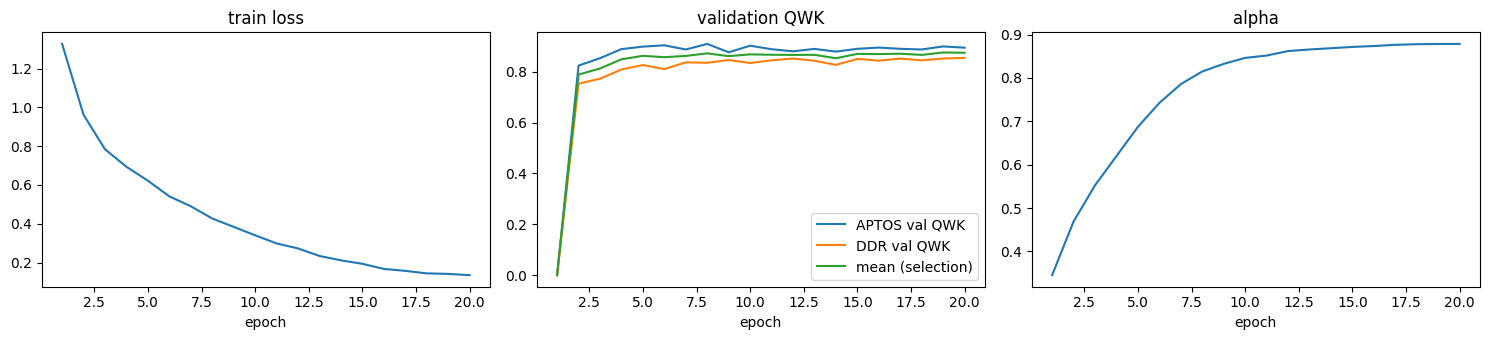

In [ ]:
import matplotlib.pyplot as plt
lg = pd.read_csv(f"{BASE_PATH}/train_log_{RUN}.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(lg.epoch, lg.train_loss); ax[0].set_title("train loss")
ax[1].plot(lg.epoch, lg.aptos_qwk, label="APTOS val QWK"); ax[1].plot(lg.epoch, lg.ddr_qwk, label="DDR val QWK")
ax[1].plot(lg.epoch, lg.sel_qwk, label="mean (selection)"); ax[1].legend(); ax[1].set_title("validation QWK")
ax[2].plot(lg.epoch, lg.alpha); ax[2].set_title("alpha")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [ ]:
import sys, torch, timm, pennylane, sklearn, albumentations, numpy, pandas
print("python", sys.version.split()[0], "| torch", torch.__version__, "| timm", timm.__version__, "| pennylane", pennylane.__version__,
         "| sklearn", sklearn.__version__, "| albumentations", albumentations.__version__, "| numpy", numpy.__version__, "| pandas", pandas.__version__)
print(torch.cuda.get_device_name(0))

python 3.13.15 | torch 2.11.0+cu130 | timm 1.0.30 | pennylane 0.45.1 | sklearn 1.6.1 | albumentations 2.0.8 | numpy 2.1.3 | pandas 2.2.3
Tesla T4
